In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [ ]:

df = pd.read_csv(
    '/content/training.1600000.processed.noemoticon.csv',
    encoding='latin-1',
    header=None,
    names=['target', 'id', 'date', 'flag', 'user', 'text'],
    engine='python',
    on_bad_lines='warn'
)

print("Dataset shape:", df.shape)
df.head()


Dataset shape: (1600000, 6)


,target,id,date,flag,user,text
0,0,1467810369,Mon Apr 06 22:19:45 PDT 2009,NO_QUERY,_TheSpecialOne_,"@switchfoot http://twitpic.com/2y1zl - Awww, t..."
1,0,1467810672,Mon Apr 06 22:19:49 PDT 2009,NO_QUERY,scotthamilton,is upset that he can't update his Facebook by ...
2,0,1467810917,Mon Apr 06 22:19:53 PDT 2009,NO_QUERY,mattycus,@Kenichan I dived many times for the ball. Man...
3,0,1467811184,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,ElleCTF,my whole body feels itchy and like its on fire
4,0,1467811193,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,Karoli,"@nationwideclass no, it's not behaving at all...."


inspecting the dataset more

In [ ]:

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nSentiment label counts:")
print(df['target'].value_counts(dropna=False))

print("\nSample tweets:")
df[['target', 'text']].head(5)


Dataset shape: (1600000, 6)

Column names:
['target', 'id', 'date', 'flag', 'user', 'text']

Sentiment label counts:
target
0    800000
4    800000
Name: count, dtype: int64

Sample tweets:


,target,text
0,0,"@switchfoot http://twitpic.com/2y1zl - Awww, t..."
1,0,is upset that he can't update his Facebook by ...
2,0,@Kenichan I dived many times for the ball. Man...
3,0,my whole body feels itchy and like its on fire
4,0,"@nationwideclass no, it's not behaving at all...."


In [ ]:

# Retain only the required columns
df = df[['target', 'text']].copy()

# Remove missing values and duplicate records
df = df.dropna(subset=['target', 'text'])
df = df.drop_duplicates()

# Keep only the standard Sentiment140 labels
df = df[df['target'].isin([0, 4])].copy()

print("Dataset shape after cleaning:", df.shape)

print("\nSentiment counts:")
print(df['target'].value_counts())

print("\nSample records:")
df.head()


Dataset shape after cleaning: (1583691, 2)

Sentiment counts:
target
4    793506
0    790185
Name: count, dtype: int64

Sample records:


,target,text
0,0,"@switchfoot http://twitpic.com/2y1zl - Awww, t..."
1,0,is upset that he can't update his Facebook by ...
2,0,@Kenichan I dived many times for the ball. Man...
3,0,my whole body feels itchy and like its on fire
4,0,"@nationwideclass no, it's not behaving at all...."


In [ ]:

df['target'] = df['target'].map({
    0: 'negative',
    4: 'positive'
})

print("Sentiment counts:")
print(df['target'].value_counts())

df.head()


Sentiment counts:
target
positive    793506
negative    790185
Name: count, dtype: int64


,target,text
0,negative,"@switchfoot http://twitpic.com/2y1zl - Awww, t..."
1,negative,is upset that he can't update his Facebook by ...
2,negative,@Kenichan I dived many times for the ball. Man...
3,negative,my whole body feels itchy and like its on fire
4,negative,"@nationwideclass no, it's not behaving at all...."


In [ ]:

X = df['text']
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())


Training samples: 1266952
Testing samples: 316739

Training sentiment distribution:
target
positive    634804
negative    632148
Name: count, dtype: int64

Testing sentiment distribution:
target
positive    158702
negative    158037
Name: count, dtype: int64


In [ ]:

vectorizer = CountVectorizer(
    max_features=5000,
    stop_words='english'
)

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print("Training feature matrix:", X_train_vec.shape)
print("Testing feature matrix:", X_test_vec.shape)
print("\nSample vocabulary words:")
print(vectorizer.get_feature_names_out()[:20])


Training feature matrix: (1266952, 5000)
Testing feature matrix: (316739, 5000)

Sample vocabulary words:
['00' '000' '04' '05' '06' '07' '08' '09' '10' '100' '1000' '100th' '101'
 '10am' '10pm' '10th' '11' '11am' '11pm' '11th']


In [ ]:

model = MultinomialNB()

model.fit(X_train_vec, y_train)

print("Naive Bayes model trained successfully.")


Naive Bayes model trained successfully.


In [ ]:

y_pred = model.predict(X_test_vec)

print("Predictions completed successfully.")

print("\nFirst 10 actual sentiments:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted sentiments:")
print(y_pred[:10].tolist())


Predictions completed successfully.

First 10 actual sentiments:
['negative', 'positive', 'negative', 'negative', 'negative', 'negative', 'positive', 'positive', 'negative', 'positive']

First 10 predicted sentiments:
['negative', 'positive', 'negative', 'negative', 'negative', 'negative', 'negative', 'positive', 'positive', 'positive']


In [ ]:

accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.4f}")
print(f"Model Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Model Accuracy: 0.7555
Model Accuracy: 75.55%

Classification Report:
              precision    recall  f1-score   support

    negative       0.76      0.75      0.75    158037
    positive       0.75      0.76      0.76    158702

    accuracy                           0.76    316739
   macro avg       0.76      0.76      0.76    316739
weighted avg       0.76      0.76      0.76    316739



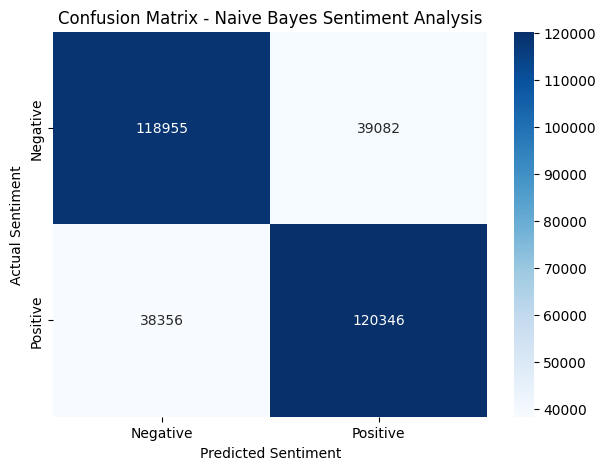

In [ ]:

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['negative', 'positive']
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.title('Confusion Matrix - Naive Bayes Sentiment Analysis')
plt.show()


In [ ]:

new_tweets = [
    "I absolutely love this movie, it is amazing!",
    "I am very disappointed and unhappy with this service.",
    "The weather is okay today."
]

new_tweets_vec = vectorizer.transform(new_tweets)
new_predictions = model.predict(new_tweets_vec)

for tweet, sentiment in zip(new_tweets, new_predictions):
    print("Tweet:", tweet)
    print("Predicted sentiment:", sentiment)
    print()


Tweet: I absolutely love this movie, it is amazing!
Predicted sentiment: positive

Tweet: I am very disappointed and unhappy with this service.
Predicted sentiment: negative

Tweet: The weather is okay today.
Predicted sentiment: negative

